# Tema 3 · NumPy: pensar en arreglos

Vectores, matrices y tensores para operar con muchos números a la vez.

Este cuaderno es el tema 3 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/3-numpy-pensar-en-arreglos/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Una foto de celular tiene unos 12 millones de píxeles, y cada píxel son tres números: cuánto rojo, cuánto verde y cuánto azul. Si quieres aclarar la foto, tienes que sumarle algo a 36 millones de números. Con lo que aprendiste en el tema 2, escribirías un bucle que recorre los números uno por uno. ¿Cuánto tardaría? ¿Y si son mil fotos?

Los modelos de inteligencia artificial hacen esto todo el tiempo: una red neuronal recibe lotes de imágenes, textos convertidos en números o tablas con miles de filas, y los transforma con sumas y multiplicaciones. Nadie escribe esos bucles a mano. Se usa **NumPy**, una librería de Python que guarda muchos números juntos en un **arreglo** y opera con todos a la vez, mucho más rápido. Casi todas las herramientas de IA que vas a usar en la ruta (pandas, scikit-learn, PyTorch) están construidas sobre esta misma idea.

En este tema vas a:

- crear arreglos de una a cuatro dimensiones, y leer su **forma** (`shape`) y su **tipo** (`dtype`);
- sacar partes de un arreglo con índices, rebanadas y condiciones;
- sumar y promediar **por ejes**, y predecir la forma del resultado;
- entender el **broadcasting**, la regla con la que NumPy opera con arreglos de formas distintas;
- usar el **producto punto** para medir qué tan parecidos son dos vectores, y multiplicar matrices;
- tratar una foto como un arreglo: recortarla, voltearla y pasarla a gris;
- cambiar un bucle por una operación vectorizada y medir cuánto se acelera.

Necesitas lo del tema 2: listas, bucles `for`, funciones e `import`.

## Actividad: estirar formas

Antes de escribir código, juega con la regla más importante del tema. Cuando sumas dos arreglos de formas distintas, NumPy intenta **estirar** el más chico copiándolo, hasta que los dos tengan la misma forma. A eso se le llama **broadcasting**. Una forma se escribe entre paréntesis: `(3, 1)` es una tabla de 3 filas y 1 columna; `(4,)` es una fila suelta de 4 números.

En el primer panel eliges la forma de *A* y la de *B* y ves cómo se estiran hasta la forma de *A* + *B*. Las celdas con borde continuo son los números que de verdad existen; las de borde punteado son copias. El segundo panel es una tabla de 3 × 4 que puedes sumar «por el eje 0» o «por el eje 1».

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/3-numpy-pensar-en-arreglos/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Empieza con *A* = `(3, 1)` y *B* = `(1, 4)`. ¿Cuántas veces se copia la columna de *A*? ¿Y la fila de *B*? ¿Qué forma tiene el resultado?
2. Cambia *B* a `(4,)`. ¿Cambia el resultado? Mira la tabla de formas: ¿qué número aparece en gris al lado izquierdo de *B*?
3. Pon *A* = `(3, 4)` y *B* = `(3,)`. ¿Qué dimensión choca? Busca un *B* que sí funcione con ese *A*.
4. Prueba *A* = `(3,)` y *B* = `(3, 1)`. ¿Te sorprende la forma del resultado?
5. En el segundo panel, suma por el eje 0 y después por el eje 1. ¿Qué forma tiene cada resultado? ¿Qué dimensión de la tabla desaparece en cada caso?

Si en el paso 3 encontraste que `(3, 4)` funciona con `(4,)` o con `(3, 1)`, pero no con `(3,)`, ya descubriste la regla. Al final de la sección de broadcasting está escrita con todas sus letras.

## De la lista al arreglo

Un arreglo de NumPy se parece a una lista, pero se comporta distinto. Compara:

In [ ]:
import numpy as np

lista = [1, 2, 3, 4]
arreglo = np.array([1, 2, 3, 4])

print(lista * 2)     # la lista repetida dos veces
print(arreglo * 2)   # cada número multiplicado por 2
print(arreglo + 10)
print(arreglo ** 2)

[1, 2, 3, 4, 1, 2, 3, 4]
[2 4 6 8]
[11 12 13 14]
[ 1  4  9 16]


Con una lista, `* 2` repite la lista. Con un arreglo, la operación se aplica **a cada número**: se dice que es una operación **elemento a elemento** o **vectorizada**. No hace falta escribir ningún bucle.

La costumbre es importar NumPy con el nombre corto `np`. Para el resto del tema vamos a usar las notas de un curso, como las del analizador del tema 2, pero ahora guardadas en un arreglo de dos dimensiones: una fila por estudiante y una columna por materia.

In [ ]:
materias = ["Matemática", "Física", "Lenguaje", "Biología"]
# Notas sobre 100: una fila por estudiante, una columna por materia
notas = np.array([
    [72, 65, 80, 58],
    [45, 50, 62, 70],
    [88, 92, 75, 81],
    [60, 48, 55, 66],
    [95, 85, 90, 88],
    [38, 52, 47, 61],
])

print("shape:", notas.shape)   # (filas, columnas)
print("ndim: ", notas.ndim)    # cuántas dimensiones tiene
print("size: ", notas.size)    # cuántos números hay en total
print("dtype:", notas.dtype)   # de qué tipo es cada número
print("En décimos:", (notas / 10).dtype)

shape: (6, 4)
ndim:  2
size:  24
dtype: int64
En décimos: float64


Estas cuatro propiedades describen cualquier arreglo:

- **`shape`** (forma): cuántos elementos hay en cada dimensión. `(6, 4)` son 6 filas y 4 columnas. Es lo más importante que tienes que saber de un arreglo, y lo que más vas a mirar cuando algo falle.
- **`ndim`**: cuántas dimensiones tiene. Un arreglo de una dimensión se llama **vector**; de dos, **matriz**; de tres o más, **tensor**.
- **`size`**: cuántos números hay en total, el producto de la forma (6 × 4 = 24).
- **`dtype`**: el tipo de **todos** los números. A diferencia de una lista, un arreglo no mezcla tipos. `int64` son enteros y `float64`, números con decimales; al dividir, NumPy pasa a `float64`. Más adelante vas a ver `uint8`, los enteros de 0 a 255 de las imágenes.

### Otras formas de crear arreglos

No siempre se escriben los números a mano. Estas funciones crean arreglos de la forma que les pidas:

In [ ]:
print(np.zeros((2, 3)))          # una tabla de ceros de 2 × 3
print(np.ones(4))                # cuatro unos
print(np.arange(0, 10, 2))       # como range, pero da un arreglo
print(np.linspace(0, 1, 5))      # 5 números parejos de 0 a 1

# Números al azar, con semilla fija para que salgan siempre iguales
rng = np.random.default_rng(42)
print(rng.integers(1, 7, size=10))          # diez dados
# Números al azar alrededor de 0, casi todos entre -2 y 2: la
# «campana» de la distribución normal, que verás en el tema 5
print(rng.normal(0, 1, size=(2, 3)).round(2))

[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1. 1.]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[1 5 4 3 3 6 1 5 2 1]
[[-1.3   0.13 -0.32]
 [-0.02 -0.85  0.88]]


`np.random.default_rng(42)` crea un **generador de números aleatorios** con la semilla 42. Con la misma semilla, los números «al azar» salen siempre iguales: así cualquiera puede repetir tus resultados. Lo vas a usar en todos los temas de la ruta.

## Indexar, rebanar y filtrar

Para leer partes de un arreglo se usan corchetes, como con las listas. En una matriz van **dos índices separados por coma**: primero la fila y después la columna. Se empieza a contar desde 0.

In [ ]:
print(notas[0])          # la fila 0: el primer estudiante
print(notas[0, 2])       # fila 0, columna 2: su nota de Lenguaje
print(notas[-1])         # la última fila
print(notas[:, 0])       # todas las filas, columna 0: Matemática
print(notas[1:3, :2])    # filas 1 y 2, columnas 0 y 1
print(notas[::2, -1])    # una fila sí y otra no, última columna

[72 65 80 58]
80
[38 52 47 61]
[72 45 88 60 95 38]
[[45 50]
 [88 92]]
[58 81 88]


Una **rebanada** `inicio:fin:paso` funciona como en las listas: incluye el inicio, no incluye el fin, y si omites algo se usa el valor de siempre (desde el principio, hasta el final, de uno en uno). Un `:` solo significa «todo en esta dimensión». Fíjate en las formas: `notas[0]` es un vector de 4 números, y `notas[1:3, :2]` es una matriz de 2 × 2.

Una advertencia: una rebanada **no es una copia**, es una ventana al mismo arreglo. Si cambias un número de la rebanada, cambia también en `notas`. Si quieres una copia independiente, usa `.copy()`, por ejemplo `primera = notas[0].copy()`.

### Filtrar con condiciones

Una comparación con un arreglo da un arreglo de `True` y `False`, del mismo tamaño. Ese arreglo sirve como índice: se queda solo con los números donde hay `True`. A esto se le llama **indexación booleana**. Supongamos que en este curso se aprueba con 51 o más.

In [ ]:
aprobado = notas >= 51
print(aprobado[:2])                  # las dos primeras filas
print("Notas reprobadas:", notas[notas < 51])
print("Cuántas notas aprobadas:", aprobado.sum())
# Las notas de Matemática de quienes aprobaron Física
print(notas[notas[:, 1] >= 51, 0])

[[ True  True  True  True]
 [False False  True  True]]
Notas reprobadas: [45 50 48 38 47]
Cuántas notas aprobadas: 19
[72 88 95 38]


`True` cuenta como 1 y `False` como 0, por eso `aprobado.sum()` cuenta los `True`. En el tema 2, cada una de estas líneas era un bucle con un `if` adentro.

## Los ejes

Cada dimensión de un arreglo es un **eje**, numerado desde 0. En una matriz, el **eje 0** recorre las filas (va hacia abajo) y el **eje 1** recorre las columnas (va hacia la derecha). Muchas funciones, como `sum`, `mean`, `max` o `argmax`, aceptan `axis=` para operar **a lo largo** de un eje.

In [ ]:
M = np.array([[2, 5, 1, 4],
              [3, 0, 6, 2],
              [1, 4, 2, 7]])

print("Sin eje:  ", M.sum())
print("axis=0:   ", M.sum(axis=0), "forma", M.sum(axis=0).shape)
print("axis=1:   ", M.sum(axis=1), "forma", M.sum(axis=1).shape)

Sin eje:   37
axis=0:    [ 6  9  9 13] forma (4,)
axis=1:    [12 11 14] forma (3,)


La forma de `M` es `(3, 4)`. Con `axis=0` se suma hacia abajo: el eje 0 desaparece y queda un número por columna, forma `(4,)`. Con `axis=1` se suma hacia la derecha: desaparece el eje 1 y queda un número por fila, forma `(3,)`. La regla para predecir la forma es **tachar el eje** que pides. Este código dibuja el esquema:

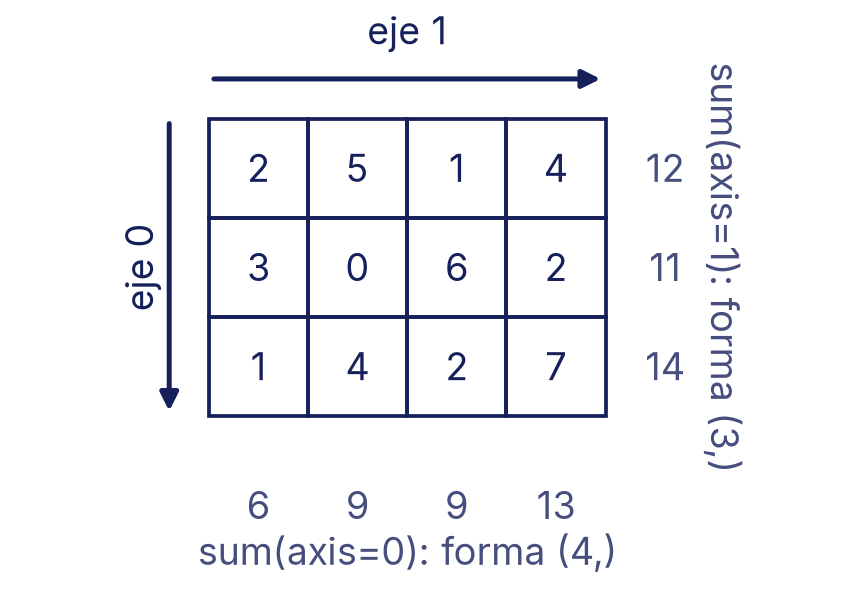

In [ ]:
import matplotlib.pyplot as plt

filas, columnas = M.shape
fig, ax = plt.subplots()
for i in range(filas):
    for j in range(columnas):
        # La fila i se dibuja más abajo cuanto mayor es i
        ax.add_patch(plt.Rectangle((j, -i), 1, 1, fill=False,
                                   edgecolor="C0", linewidth=1.5))
        ax.text(j + 0.5, -i + 0.5, M[i, j], ha="center", va="center")
for j, s in enumerate(M.sum(axis=0)):
    ax.text(j + 0.5, -filas + 0.1, s, ha="center", va="center",
            color="C2")
for i, s in enumerate(M.sum(axis=1)):
    ax.text(columnas + 0.6, -i + 0.5, s, ha="center", va="center",
            color="C2")
# Las flechas de los ejes
flecha = dict(arrowstyle="-|>", color="C0", linewidth=2)
ax.annotate("", xy=(-0.4, -filas + 1), xytext=(-0.4, 1),
            arrowprops=flecha)
ax.annotate("", xy=(columnas, 1.4), xytext=(0, 1.4), arrowprops=flecha)
ax.text(-0.7, -0.5, "eje 0", rotation=90, ha="center", va="center")
ax.text(columnas / 2, 1.75, "eje 1", ha="center")
ax.text(columnas / 2, -filas - 0.5, "sum(axis=0): forma (4,)",
        ha="center", color="C2")
ax.text(columnas + 1.2, -filas / 2 + 1, "sum(axis=1): forma (3,)",
        rotation=-90, ha="center", va="center", color="C2")
ax.set_xlim(-1, columnas + 1.5)
ax.set_ylim(-filas - 0.9, 2.1)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

Con las notas, los ejes responden preguntas distintas. `zip` recorre dos listas (o arreglos) a la vez: en cada vuelta toma un elemento de cada una, aquí una materia y su promedio:

In [ ]:
prom_materia = notas.mean(axis=0)     # un promedio por materia
prom_estudiante = notas.mean(axis=1)  # un promedio por estudiante

for materia, p in zip(materias, prom_materia):
    print(f"{materia:<11} {p:5.1f}")
print("Por estudiante:", prom_estudiante.round(1))
print("Mejor estudiante: fila", prom_estudiante.argmax())
print("Nota más alta de cada materia:", notas.max(axis=0))

Matemática   66.3
Física       65.3
Lenguaje     68.2
Biología     70.7
Por estudiante: [68.8 56.8 84.  57.2 89.5 49.5]
Mejor estudiante: fila 4
Nota más alta de cada materia: [95 92 90 88]


`argmax` da la **posición** del máximo, no el máximo. En arreglos de más dimensiones la regla es la misma: si un arreglo tiene forma `(2, 3, 4)`, `sum(axis=1)` tacha el 3 y da `(2, 4)`, y `sum(axis=(0, 2))` tacha el 2 y el 4 y da `(3,)`.

## Cambiar la forma: reshape y transpuesta

Los mismos números se pueden ordenar en otra forma con **`reshape`**, siempre que la cantidad total no cambie. La **transpuesta** `.T` intercambia filas y columnas.

In [ ]:
a = np.arange(12)
print(a, a.shape)

b = a.reshape(3, 4)
print(b)
print("b.T:", b.T.shape)
print(b.T)
print(a.reshape(2, 2, 3).shape)
print(a.reshape(-1, 6).shape)    # -1: «calcula tú este número»

[ 0  1  2  3  4  5  6  7  8  9 10 11] (12,)
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
b.T: (4, 3)
[[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]
(2, 2, 3)
(2, 6)


`reshape` lee los números en orden, fila por fila, y los vuelve a acomodar. Como 12 = 3 × 4 = 2 × 2 × 3, esas formas funcionan; `a.reshape(5, 2)` daría un error, porque 5 × 2 = 10 y no 12. Un `-1` en una de las dimensiones le pide a NumPy que la calcule: 12 / 6 = 2. En un arreglo de más de dos dimensiones, `.T` invierte el orden de **todos** los ejes: una forma `(2, 3, 4)` pasa a `(4, 3, 2)`.

## Broadcasting: operar con formas distintas

Ya usaste broadcasting sin darte cuenta: en `arreglo + 10`, el número 10 se «estiró» hasta tener la forma de `arreglo`. Lo mismo pasa entre arreglos. Por ejemplo, para ver qué estudiante está por encima o por debajo del promedio de cada materia, restamos a cada fila el vector de promedios:

In [ ]:
print(notas.shape, prom_materia.shape)
diferencia = notas - prom_materia      # (6, 4) - (4,)
print(diferencia[:2].round(1))

(6, 4) (4,)
[[  5.7  -0.3  11.8 -12.7]
 [-21.3 -15.3  -6.2  -0.7]]


NumPy restó el vector de 4 promedios a **cada una** de las 6 filas, como si lo hubiera copiado 6 veces hacia abajo (en realidad no copia nada en memoria, por eso es rápido). Ahora intentemos lo mismo con los estudiantes: restar a cada estudiante su propio promedio.

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
print(prom_estudiante.shape)
notas - prom_estudiante                # (6, 4) - (6,)

(6,)
Traceback (most recent call last):
  ...
ValueError: operands could not be broadcast together with shapes (6,4) (6,) 


No funciona, y la regla explica por qué. Para operar con dos arreglos, NumPy:

1. **Alinea las formas por la derecha.** Si una tiene menos dimensiones, le agrega unos (1) a la izquierda: `(6,)` frente a `(6, 4)` se convierte en `(1, 6)`.
2. **Compara cada par de dimensiones, de derecha a izquierda.** Son compatibles si **son iguales** o si **una de las dos es 1**.
3. **Estira los 1** copiando, hasta la otra medida. La forma del resultado es la mayor de cada par.

| | penúltima | última | |
|---|---|---|---|
| `notas - prom_materia` | 6 y (1) | 4 y 4 | compatible: `(6, 4)` |
| `notas - prom_estudiante` | 6 y (1) | **4 y 6** | choca |

El vector de 6 promedios queda alineado con las 4 columnas, y 4 y 6 ni son iguales ni tienen un 1. La solución es darle la forma `(6, 1)`, una columna, para que se estire hacia la derecha. Hay dos maneras: pedir `keepdims=True` al promediar, que conserva el eje tachado con tamaño 1, o agregar un eje con `np.newaxis`.

In [ ]:
prom_col = notas.mean(axis=1, keepdims=True)
print(prom_col.shape)                              # (6, 1)
print((notas - prom_col)[:2].round(1))
# Lo mismo, agregando un eje al vector de forma (6,)
print(prom_estudiante[:, np.newaxis].shape)

(6, 1)
[[  3.2  -3.8  11.2 -10.8]
 [-11.8  -6.8   5.2  13.2]]
(6, 1)


Cuando una operación falla o da una forma rara, escribe las dos formas una debajo de la otra, alineadas por la derecha, y compáralas columna por columna. Es lo mismo que hace la actividad de arriba.

## Producto punto: medir el parecido

Imagina que tres estudiantes, Ana, Beto y Caro, puntúan de 0 a 5 cuánto les gustan cuatro cosas: fútbol, música, lectura y videojuegos. Cada estudiante es un **vector** de 4 números. ¿Quién se parece más a quién?

El **producto punto** de dos vectores multiplica término a término y suma todo:

$$a \cdot b = {a}_{1} {b}_{1} + {a}_{2} {b}_{2} + \cdots + {a}_{n} {b}_{n}$$

Es grande cuando los dos vectores tienen números grandes **en los mismos lugares**: cuando a los dos les gusta mucho lo mismo. En NumPy se escribe `a @ b` (o `np.dot(a, b)`).

In [ ]:
# fútbol, música, lectura, videojuegos
ana = np.array([5, 1, 0, 4])
beto = np.array([4, 0, 1, 5])
caro = np.array([0, 5, 4, 1])

print("Ana · Beto =", ana @ beto)
print("Ana · Caro =", ana @ caro)
print("A mano:    ", np.sum(ana * beto))

Ana · Beto = 40
Ana · Caro = 9
A mano:     40


Pero el producto punto también crece si alguien pone notas altas a todo. Para medir solo el **parecido**, ayuda ver cada vector como una **flecha** que sale del origen. Con dos gustos nada más, fútbol y música, se puede dibujar: Ana es la flecha que llega al punto (5, 1), Beto la que llega a (4, 0) y Caro la que llega a (0, 5).

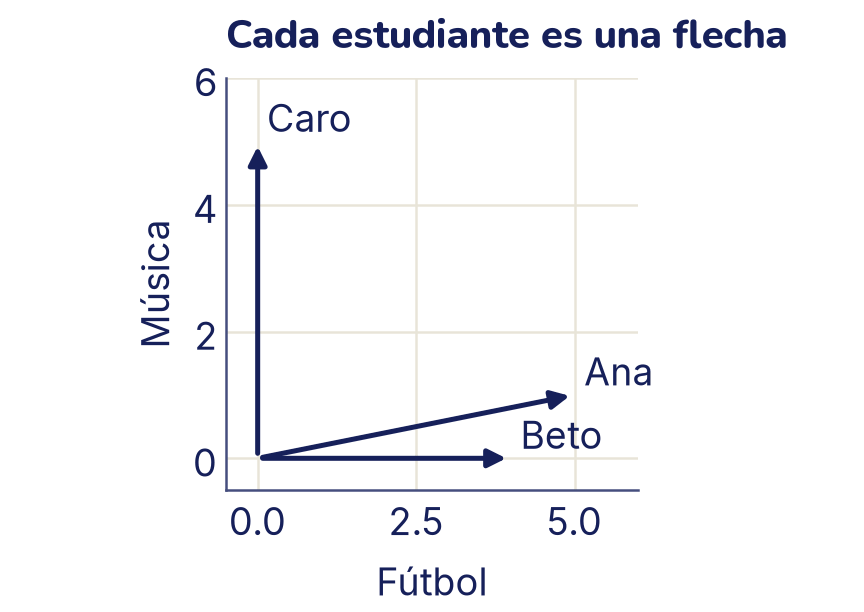

In [ ]:
# Solo los dos primeros gustos (fútbol y música), para dibujar en el plano
for nombre, v in [("Ana", ana[:2]), ("Beto", beto[:2]),
                  ("Caro", caro[:2])]:
    plt.annotate("", xy=v, xytext=(0, 0),
                 arrowprops=dict(arrowstyle="-|>", color="C0", lw=2))
    plt.text(v[0] + 0.15, v[1] + 0.15, nombre)
# Solo para dibujar:
plt.gca().set_aspect("equal")
plt.xlim(-0.5, 6)
plt.ylim(-0.5, 6)
plt.xlabel("Fútbol")
plt.ylabel("Música")
plt.title("Cada estudiante es una flecha")
plt.show()

Las flechas de Ana y Beto apuntan casi hacia el mismo lado: les gusta lo mismo y en la misma proporción. La de Caro forma casi un ángulo recto con ellas. El **largo** de cada flecha se llama **norma** y sale de Pitágoras: la flecha de Ana es la hipotenusa de un triángulo de catetos 5 y 1, así que mide √(5² + 1²) = √26 ≈ 5,10. Con más números la cuenta es la misma: cada uno al cuadrado, se suman y se saca la raíz. Para medir el parecido, el producto punto se divide entre las dos normas:

$$\| a \| = \sqrt{{a}_{1}^{2} + \cdots + {a}_{n}^{2}} \qquad \text{parecido} = \frac{a \cdot b}{\| a \| \; \| b \|}$$

Ese cociente es el **coseno del ángulo** entre las dos flechas, y por eso se llama **similitud coseno**: si apuntan exactamente hacia el mismo lado (ángulo 0°), vale 1; si son perpendiculares (90°), vale 0, y si son opuestas (180°), vale −1. Como los gustos van de 0 a 5 y nunca son negativos, aquí siempre sale entre 0 y 1. El ángulo no depende del largo: quien pone notas altas a todo tiene una flecha más larga, pero apunta hacia el mismo lado. Es la misma idea con la que, en la fase 5, un modelo de lenguaje decide que «perro» se parece más a «gato» que a «mesa».

In [ ]:
def parecido(a, b):
    """Similitud coseno: el producto punto de los vectores normalizados."""
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

print(f"Norma de Ana: {np.linalg.norm(ana):.2f}")
print(f"Ana y Beto: {parecido(ana, beto):.2f}")
print(f"Ana y Caro: {parecido(ana, caro):.2f}")

Norma de Ana: 6.48
Ana y Beto: 0.95
Ana y Caro: 0.21


### Normalizar filas y multiplicar matrices

Si apilamos los tres vectores en una matriz, podemos **normalizar cada fila** (dividirla entre su norma) de una vez, con broadcasting: la norma de cada fila con `keepdims=True` tiene forma `(3, 1)`. Después, una sola **multiplicación de matrices** calcula el parecido de todos con todos.

In [ ]:
G = np.array([ana, beto, caro])                  # forma (3, 4)
normas = np.linalg.norm(G, axis=1, keepdims=True)  # forma (3, 1)
G_unit = G / normas                              # cada fila mide 1
print(np.linalg.norm(G_unit, axis=1))

similitudes = G_unit @ G_unit.T                  # (3, 4) @ (4, 3)
print(similitudes.shape)
print(similitudes.round(2))

[1. 1. 1.]
(3, 3)
[[1.   0.95 0.21]
 [0.95 1.   0.21]
 [0.21 0.21 1.  ]]


La fila *i*, columna *j* del resultado es el producto punto de la fila *i* de la primera matriz con la columna *j* de la segunda. Por eso las medidas de adentro tienen que coincidir: **(m, n) @ (n, p) da (m, p)**. Aquí, `(3, 4) @ (4, 3)` da `(3, 3)`. La diagonal vale 1 (cada uno se parece totalmente a sí mismo) y la matriz es simétrica.

### Una matriz por un vector transforma el vector

Una matriz de 2 × 2 multiplicada por un punto del plano da otro punto del plano. Si aplicas la misma matriz a todos los puntos de una figura, la figura se estira, se inclina o gira: la matriz es una **transformación**. Las capas de una red neuronal (tema 16) son exactamente esto, matrices que transforman vectores, una tras otra.

T @ v = [0.5 1. ]


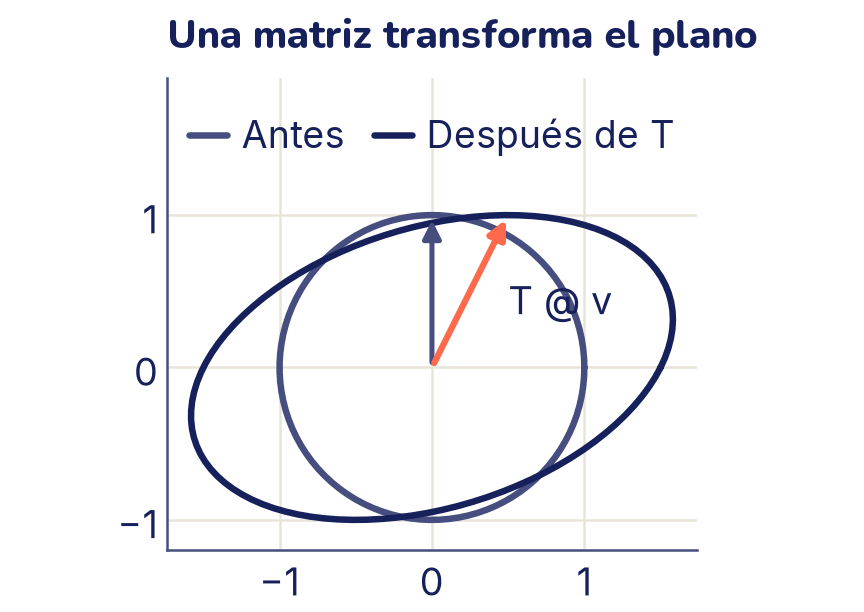

In [ ]:
T = np.array([[1.5, 0.5],
              [0.0, 1.0]])
angulos = np.linspace(0, 2 * np.pi, 100)
# 100 puntos de un círculo, uno por columna: forma (2, 100)
circulo = np.array([np.cos(angulos), np.sin(angulos)])
transformado = T @ circulo                       # (2, 2) @ (2, 100)

v = np.array([0.0, 1.0])
print("T @ v =", T @ v)

plt.plot(circulo[0], circulo[1], color="C2", label="Antes")
plt.plot(transformado[0], transformado[1], color="C0",
         label="Después de T")
plt.annotate("", xy=v, xytext=(0, 0),
             arrowprops=dict(arrowstyle="-|>", color="C2", lw=2))
plt.annotate("", xy=T @ v, xytext=(0, 0),
             arrowprops=dict(arrowstyle="-|>", color="C1", lw=2.5))
plt.text(0.5, 0.35, "T @ v")
plt.gca().set_aspect("equal")
plt.ylim(-1.2, 1.9)
plt.title("Una matriz transforma el plano")
# Muestras cortas para que la leyenda quepa dentro del eje
plt.legend(loc="upper center", ncol=2, handlelength=1.0,
           handletextpad=0.4, columnspacing=0.8)
plt.show()

El punto (0, 1) pasó a (0,5; 1). A mano, cada fila de `T` hace un producto punto con `v`: (1,5 · 0 + 0,5 · 1; 0 · 0 + 1 · 1) = (0,5; 1). Es decir, la matriz empuja hacia la derecha lo que está arriba y estira en horizontal. Todo el círculo se convirtió en una elipse inclinada con **una sola** multiplicación de matrices, sin recorrer los 100 puntos.

## Una imagen es un arreglo

Para la computadora, una foto en color es un tensor de tres dimensiones: **alto × ancho × 3**, un número de 0 a 255 por cada canal de color (rojo, verde, azul) de cada píxel. scikit-learn trae dos fotos de ejemplo, así que no hace falta descargar nada.

In [ ]:
from sklearn.datasets import load_sample_image

foto = load_sample_image("china.jpg")
print(type(foto).__name__, foto.shape, foto.dtype)
print("Píxel de arriba a la izquierda (R, G, B):", foto[0, 0])
print("Valor más chico y más grande:", foto.min(), foto.max())

ndarray (427, 640, 3) uint8
Píxel de arriba a la izquierda (R, G, B): [174 201 231]
Valor más chico y más grande: 0 255


La foto mide 427 píxeles de alto y 640 de ancho, y cada número es un `uint8`: un entero sin signo de 8 bits (8 cifras binarias, que alcanzan para 256 valores), de 0 a 255. Todo lo que aprendiste sirve tal cual:

- **Recortar** es rebanar filas y columnas.
- **Voltear** como en un espejo es recorrer las columnas al revés, con paso −1.
- **Pasar a gris** es un promedio ponderado de los tres canales: el ojo es más sensible al verde, así que pesa más. Es un tensor por un vector: `(427, 640, 3) @ (3,)` da `(427, 640)`, porque el `@` hace el producto punto de la última dimensión (los 3 canales de cada píxel) con los pesos.

(240, 320, 3) (427, 640, 3) (427, 640)


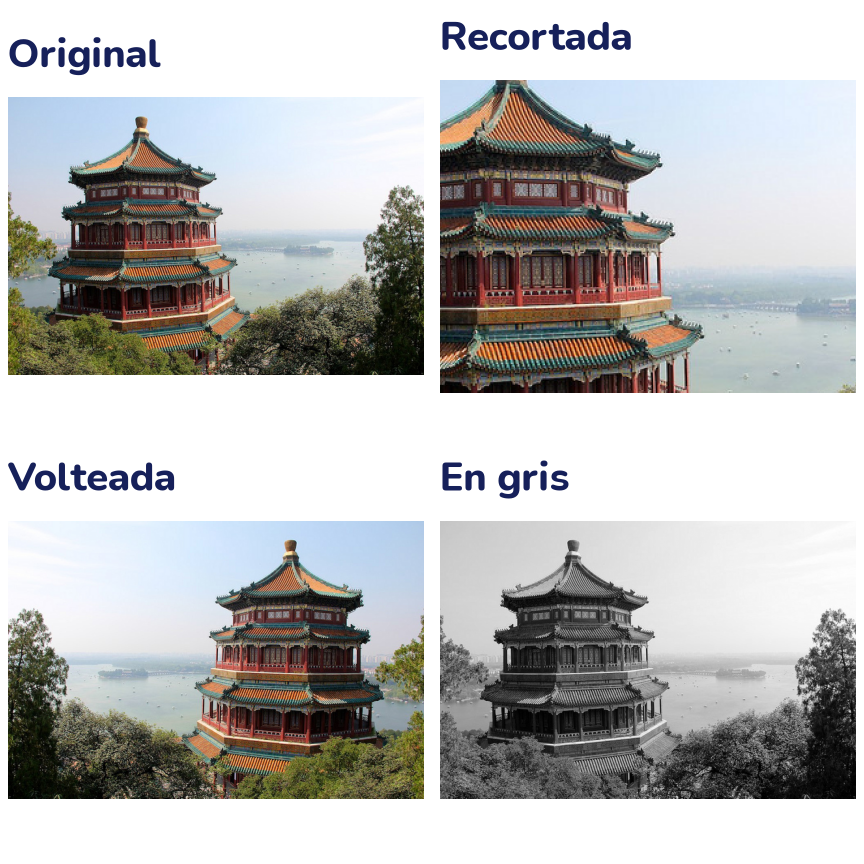

In [ ]:
recorte = foto[60:300, 150:470]      # filas 60 a 299, columnas 150 a 469
espejo = foto[:, ::-1]               # las columnas, de atrás para adelante
pesos = np.array([0.299, 0.587, 0.114])
gris = foto @ pesos                  # un número por píxel
print(recorte.shape, espejo.shape, gris.shape)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
ejes[0, 0].imshow(foto)
ejes[0, 0].set_title("Original")
ejes[0, 1].imshow(recorte)
ejes[0, 1].set_title("Recortada")
ejes[1, 0].imshow(espejo)
ejes[1, 0].set_title("Volteada")
ejes[1, 1].imshow(gris, cmap="gray")
ejes[1, 1].set_title("En gris")
for eje in ejes.flat:
    eje.axis("off")
plt.show()

### Un lote de imágenes

Las redes neuronales no ven una foto a la vez, sino **lotes**: varias fotos del mismo tamaño apiladas en un tensor de cuatro dimensiones, **(N, alto, ancho, 3)**. `np.stack` apila arreglos de la misma forma a lo largo de un eje nuevo.

In [ ]:
lote = np.stack([foto, espejo, foto[::-1]])      # tres fotos
print("lote:", lote.shape)                        # (N, alto, ancho, 3)
print("una foto:", lote[1].shape)
print("el píxel (0, 0) de cada foto:", lote[:, 0, 0].shape)
# El color promedio de cada foto: se tachan el alto y el ancho
print(lote.mean(axis=(1, 2)).round(1))

lote: (3, 427, 640, 3)
una foto: (427, 640, 3)
el píxel (0, 0) de cada foto: (3, 3)
[[144.7 145.5 140.9]
 [144.7 145.5 140.9]
 [144.7 145.5 140.9]]


Las tres fotos tienen el mismo color promedio, como debía ser: tienen los mismos píxeles, solo que en otro orden. Así se ve un lote en PyTorch (tema 18), con la diferencia de que allá los canales suelen ir antes del alto y el ancho: `(N, 3, alto, ancho)`. Pasar de una forma a la otra es una transpuesta de ejes.

## Vectorizar: cambiar bucles por arreglos

¿Cuánto se gana de verdad? Calculemos la suma de los cuadrados de un millón de números, primero con un bucle de Python y después con NumPy, y midamos el tiempo con `time.perf_counter()`, un cronómetro de alta precisión.

In [ ]:
import time

grande = rng.random(1_000_000)        # un millón de números entre 0 y 1

inicio = time.perf_counter()
total = 0.0
for valor in grande:
    total += valor * valor
t_bucle = time.perf_counter() - inicio

inicio = time.perf_counter()
total_np = np.sum(grande * grande)
t_numpy = time.perf_counter() - inicio

print("¿Dan lo mismo?", np.isclose(total, total_np))
print("¿NumPy fue más de 10 veces más rápido?", t_bucle > 10 * t_numpy)

¿Dan lo mismo? True
¿NumPy fue más de 10 veces más rápido? True


Los tiempos cambian de una computadora a otra y de una vez a otra, por eso el código no los imprime. En la computadora donde se escribió este tema, el bucle tardó unos 75 milisegundos y NumPy menos de uno: **alrededor de 100 veces más rápido**. Agrega `print(t_bucle, t_numpy)` para ver los tuyos. En Colab hay una forma más cómoda de medir: escribe `%timeit np.sum(grande * grande)` en una celda: repite la medición muchas veces y te da el tiempo promedio.

¿Por qué tanta diferencia? En el bucle, Python revisa en cada vuelta qué tipo tiene `valor`, busca cómo multiplicarlo y crea un número nuevo. Un arreglo de NumPy guarda números de un solo tipo, juntos en la memoria, y la operación completa corre en código compilado (ya traducido al idioma de la máquina, mucho más rápido que Python), sin esas revisiones. **Vectorizar** es escribir el cálculo como operaciones sobre arreglos enteros en lugar de un bucle que visita los números uno por uno. Con datos grandes, es la diferencia entre esperar un segundo y esperar dos minutos.

## Lo que aprendiste y lo que sigue

- Un **arreglo** de NumPy guarda números de un solo `dtype` en una forma (`shape`). Un vector tiene una dimensión, una matriz dos y un tensor, tres o más: una foto es `(alto, ancho, 3)` y un lote de fotos, `(N, alto, ancho, 3)`.
- Se **indexa** con `[fila, columna]`, se **rebana** con `inicio:fin:paso` y se **filtra** con condiciones.
- Una operación por **eje** tacha ese eje de la forma: `sum(axis=0)` en una matriz de `(3, 4)` da `(4,)`.
- El **broadcasting** compara las formas de derecha a izquierda: cada par tiene que ser igual o tener un 1, que se estira. `keepdims=True` y `np.newaxis` ayudan a acomodar las formas.
- El **producto punto** mide el parecido entre vectores; dividido entre las normas, es la similitud coseno. `(m, n) @ (n, p)` da `(m, p)`, y una matriz por un vector es una transformación.
- **Vectorizar** da el mismo resultado que un bucle, decenas o cientos de veces más rápido.

En el tema 4 vas a usar **pandas**, que pone nombres a las filas y las columnas de estos arreglos para explorar datos reales. En el tema 6, el descenso de gradiente se escribe en tres líneas gracias a las operaciones vectorizadas y al producto de matrices de este tema.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables de la teoría: `np`, `plt`, `rng`, `notas`, `materias`, `ana`, `beto`, `caro`, `G_unit`, `parecido`, `foto`, `recorte`, `pesos` y `lote`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta: en este tema conviene **escribir primero la forma que esperas** y recién después comprobarla con `.shape`.

## Ejercicios

### 1. Predecir formas

Sin computadora, escribe la forma del resultado de cada línea, o «error» si NumPy no puede calcularla. Usa `a = np.zeros((2, 3, 4))`.

1. `np.arange(24).reshape(4, -1)`
2. `a.T`
3. `a.sum(axis=1)`
4. `a.mean(axis=(0, 2))`
5. `a[0]` y `a[:, 0]`
6. `np.ones((5, 1)) + np.ones(3)`
7. `np.ones((8, 1, 6)) * np.ones((7, 1))`
8. `np.ones((2, 3)) @ np.ones((3, 5))`
9. `np.ones((2, 3)) + np.ones((3, 2))`

In [ ]:
# @title Respuesta: código (doble clic para verlo)
a = np.zeros((2, 3, 4))
print("1:", np.arange(24).reshape(4, -1).shape)
print("2:", a.T.shape)
print("3:", a.sum(axis=1).shape)
print("4:", a.mean(axis=(0, 2)).shape)
print("5:", a[0].shape, a[:, 0].shape)
print("6:", (np.ones((5, 1)) + np.ones(3)).shape)
print("7:", (np.ones((8, 1, 6)) * np.ones((7, 1))).shape)
print("8:", (np.ones((2, 3)) @ np.ones((3, 5))).shape)

<details>
<summary>Respuesta</summary>

1. 24 / 4 = 6, así que el `-1` vale 6.
2. `.T` invierte el orden de todos los ejes.
3. y 4. Se tachan los ejes pedidos: el 3 en el primer caso; el 2 y el 4 en el segundo.
5. `a[0]` fija el eje 0 y deja los otros dos; `a[:, 0]` fija el eje 1.
6. Alineadas por la derecha: `(5, 1)` y `(1, 3)`. El 1 de cada lado se estira: `(5, 3)`.
7. `(7, 1)` pasa a `(1, 7, 1)`. De derecha a izquierda: 6 y 1 dan 6; 1 y 7 dan 7; 8 y 1 dan 8.
8. Las medidas de adentro coinciden (3 y 3) y quedan las de afuera: `(2, 5)`.
9. Error. La última dimensión es 3 frente a 2: ni iguales ni con un 1.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
np.ones((2, 3)) + np.ones((3, 2))

### 2. Sacar partes de un tensor

`lote` tiene forma `(3, 427, 640, 3)`: tres fotos, cada una de alto × ancho × canales. Escribe una sola expresión para cada pedido y anota la forma que esperas antes de comprobarla.

1. La tercera foto del lote.
2. El canal verde (índice 1) de todas las fotos.
3. El cuadrado de 100 × 100 píxeles de la esquina inferior derecha de cada foto, con sus tres canales.
4. La primera foto achicada: una de cada cuatro filas y una de cada cuatro columnas.
5. ¿Qué fracción de los píxeles de `foto` tiene más azul que rojo? (Pista: el promedio de un arreglo de `True` y `False` es la fracción de `True`.)
6. Crea con `np.arange` y `reshape` un arreglo de forma `(2, 3, 4, 5)` con los números del 0 en adelante. ¿Qué número está en la posición `[1, 2, 3, 4]`? ¿Por qué?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("1:", lote[2].shape)
print("2:", lote[:, :, :, 1].shape)
print("3:", lote[:, -100:, -100:].shape)
print("4:", lote[0, ::4, ::4].shape)

mas_azul = foto[:, :, 2] > foto[:, :, 0]
print(f"5: {mas_azul.mean():.2f} de los píxeles")

t = np.arange(2 * 3 * 4 * 5).reshape(2, 3, 4, 5)
print("6:", t.shape, t[1, 2, 3, 4], t.size)

<details>
<summary>Respuesta</summary>

- En el 3, `-100:` toma las últimas 100 filas y las últimas 100 columnas; el canal, que no se menciona, queda entero.
- En el 4, 427 filas de cuatro en cuatro dan 107, porque se incluye la fila 0.
- En el 5, algo más de la mitad de los píxeles (0,52) tiene más azul que rojo: el cielo y el agua ocupan buena parte de la foto.
- En el 6, `[1, 2, 3, 4]` es la última posición de cada eje, así que es el último número: 119, uno menos que los 120 que hay.

</details>

### 3. Parecido y matrices

1. Calcula a mano el producto punto de `[1, 2, 3]` y `[4, 5, 6]`, y compruébalo con `@`.
2. Dani puntúa así fútbol, música, lectura y videojuegos: `[1, 4, 5, 0]`. Normaliza su vector y calcula, con **una sola** multiplicación de matriz por vector, su parecido con Ana, Beto y Caro (usa `G_unit`). ¿A quién se parece más? ¿Qué forma tiene el resultado y por qué?
3. Eli le pone 5 a todo: `[5, 5, 5, 5]`. Compara el producto punto de Ana con Beto y de Ana con Eli. Después compara sus parecidos. ¿Cuál de las dos medidas te dice mejor quién comparte los gustos de Ana?

<details>
<summary>Respuesta</summary>

1. 1·4 + 2·5 + 3·6 = 4 + 10 + 18 = **32**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("1:", np.array([1, 2, 3]) @ np.array([4, 5, 6]))

dani = np.array([1, 4, 5, 0])
dani_unit = dani / np.linalg.norm(dani)
print("2:", G_unit.shape, "@", dani_unit.shape)
print("   Ana, Beto, Caro:", (G_unit @ dani_unit).round(2))

eli = np.array([5, 5, 5, 5])
print("3: Ana · Beto =", ana @ beto, "  Ana · Eli =", ana @ eli)
print(f"   parecido Ana-Beto: {parecido(ana, beto):.2f}"
      f"   Ana-Eli: {parecido(ana, eli):.2f}")

<details>
<summary>Respuesta (sigue)</summary>

2. `(3, 4) @ (4,)` da `(3,)`: un parecido por cada fila de `G_unit`. Dani se parece mucho a Caro y poco a Ana y a Beto.
3. Ana · Eli es más grande que Ana · Beto, solo porque Eli pone números altos a todo. El parecido corrige eso: Beto comparte los gustos de Ana mucho más que Eli. Para comparar gustos sirve el parecido, no el producto punto solo.

</details>

### 4. Tres bucles para vectorizar

Escribe cada bucle en una sola línea de NumPy, sin `for`, y comprueba que da lo mismo. Después mide con `time.perf_counter()` cuántas veces más rápida es tu versión del bucle 3.

In [ ]:
# 10 000 números al azar alrededor de 60; la mayoría, entre 30 y 90
valores = rng.normal(60, 15, size=10_000)

# Bucle 1: cada valor al cuadrado, más 1
cuadrados = []
for v in valores:
    cuadrados.append(v ** 2 + 1)

# Bucle 2: cuántos valores superan el promedio
promedio = sum(valores) / len(valores)
cuenta = 0
for v in valores:
    if v > promedio:
        cuenta += 1

# Bucle 3: pasar una imagen a gris, píxel por píxel
def gris_con_bucle(imagen):
    alto, ancho, _ = imagen.shape
    resultado = np.zeros((alto, ancho))
    for i in range(alto):
        for j in range(ancho):
            r, g, b = imagen[i, j]
            resultado[i, j] = 0.299 * r + 0.587 * g + 0.114 * b
    return resultado

In [ ]:
# @title Respuesta: código (doble clic para verlo)
cuadrados_np = valores ** 2 + 1
cuenta_np = (valores > valores.mean()).sum()
print("1:", np.allclose(cuadrados, cuadrados_np))
print("2:", cuenta, cuenta_np)

inicio = time.perf_counter()
gris_b = gris_con_bucle(recorte)
t_bucle = time.perf_counter() - inicio

inicio = time.perf_counter()
gris_v = recorte @ pesos
t_vector = time.perf_counter() - inicio

print("3:", np.allclose(gris_b, gris_v), gris_v.shape)
print("¿Más de 50 veces más rápido?", t_bucle > 50 * t_vector)

<details>
<summary>Respuesta</summary>

El bucle 3 recorre los 76 800 píxeles del recorte (240 × 320) de a uno. En la computadora donde se escribió este tema tardó algo más de una décima de segundo, y la versión vectorizada, una o dos décimas de **milisegundo**: entre 600 y 1200 veces menos, según la medición. Tus números serán otros, pero la diferencia va a ser de cientos de veces. En Colab puedes compararlos con `%timeit gris_con_bucle(recorte)` y `%timeit recorte @ pesos`.

</details>

### 5. Distancias entre todos los pares

Cuatro puntos del plano están en las filas de `P = np.array([[0, 0], [3, 4], [6, 0], [3, -4]])`. Calcula la matriz de 4 × 4 con la distancia euclidiana entre cada par de puntos, **sin bucles**. La distancia entre (x₁, y₁) y (x₂, y₂) es √((x₁ − x₂)² + (y₁ − y₂)²).

Pista: `P[:, np.newaxis, :]` tiene forma `(4, 1, 2)` y `P[np.newaxis, :, :]` tiene forma `(1, 4, 2)`. ¿Qué forma tiene su resta?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
P = np.array([[0, 0], [3, 4], [6, 0], [3, -4]])
diferencias = P[:, np.newaxis, :] - P[np.newaxis, :, :]
print("Diferencias:", diferencias.shape)
distancias = np.sqrt((diferencias ** 2).sum(axis=-1))
print(distancias)

# Comprobación con dos bucles
con_bucle = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        con_bucle[i, j] = np.linalg.norm(P[i] - P[j])
print("¿Iguales?", np.allclose(distancias, con_bucle))

<details>
<summary>Respuesta</summary>

Por broadcasting, `(4, 1, 2) - (1, 4, 2)` da `(4, 4, 2)`: para cada par (*i*, *j*), la diferencia entre el punto *i* y el punto *j*. Sumar los cuadrados en el último eje (`axis=-1` es «el último») lo tacha y deja `(4, 4)`. La matriz tiene ceros en la diagonal (cada punto está a distancia 0 de sí mismo) y es simétrica, porque de *i* a *j* hay lo mismo que de *j* a *i*. Esta misma cuenta es el corazón de los vecinos cercanos (tema 8) y del clustering (tema 14).

</details>

### 6. Escalar por materia y por estudiante

1. Escala las notas **por materia**: en cada columna, la nota más baja tiene que quedar en 0 y la más alta en 1. Usa `(notas - mínimo) / (máximo - mínimo)`, con los mínimos y máximos de cada columna.
2. Haz lo mismo **por estudiante**: en cada fila, su peor nota queda en 0 y la mejor en 1. Si te sale un `ValueError`, escribe las formas una debajo de la otra y arréglalo.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
minimo = notas.min(axis=0)                    # forma (4,)
maximo = notas.max(axis=0)
por_materia = (notas - minimo) / (maximo - minimo)
print("1:", minimo.shape, por_materia.shape)
print(por_materia[:2].round(2))

minimo = notas.min(axis=1, keepdims=True)     # forma (6, 1)
maximo = notas.max(axis=1, keepdims=True)
por_estudiante = (notas - minimo) / (maximo - minimo)
print("2:", minimo.shape, por_estudiante.shape)
print(por_estudiante[:2].round(2))

<details>
<summary>Respuesta</summary>

Por materia no hace falta nada especial: `(6, 4)` con `(4,)` estira el vector hacia abajo. Por estudiante, `notas.min(axis=1)` da `(6,)`, que choca con las 4 columnas; con `keepdims=True` es `(6, 1)` y se estira hacia la derecha. Comprueba que cada columna del primer resultado y cada fila del segundo tiene un 0 y un 1.

</details>

## Mini-proyecto: filtros de imagen

Programa cuatro filtros que reciban una foto (un arreglo de forma `(alto, ancho, 3)` y tipo `uint8`) y devuelvan otra foto de tipo `uint8`, **solo con NumPy y sin bucles**. Pruébalos con `foto` y muestra los cuatro resultados en una cuadrícula de 2 × 2 con `plt.subplots(2, 2, figsize=(4.8, 4.8))`, como en la teoría.

1. **Brillo.** Suma una cantidad a todos los números. Antes, mira qué da `foto[0, 0] + 100` y explica por qué. Para evitarlo, pasa la foto a enteros grandes con `.astype(int)`, suma, limita con `np.clip(..., 0, 255)` y vuelve a `uint8` con `.astype(np.uint8)`.
2. **Negativo.** Cada número *v* pasa a 255 − *v*: lo oscuro se vuelve claro y cada color, su opuesto.
3. **Espejo.** La mitad izquierda de la foto queda igual y la mitad derecha es su reflejo, como si hubiera un espejo vertical en el centro. (Pista: `foto.copy()` y asignar a una rebanada.)
4. **Pixelado.** Divide la foto en bloques de 16 × 16 píxeles y pinta cada bloque con su color promedio. Recorta primero la foto para que el alto y el ancho sean múltiplos de 16. Pista: con `reshape`, un arreglo de `(416, 640, 3)` se puede ver como `(26, 16, 40, 16, 3)`; ¿qué ejes tienes que promediar? Para volver al tamaño original, usa `np.repeat(chica, 16, axis=0)` y lo mismo con `axis=1`.

Para ir más allá: haz que tus filtros funcionen también con todo `lote` a la vez, un arreglo de cuatro dimensiones. ¿Cuáles funcionan sin cambios? ¿Qué hay que cambiar en el pixelado?

In [ ]:
# @title Una solución de referencia, para comparar con la tuya: código (doble clic para verlo)
print("foto[0, 0] + 100 =", foto[0, 0] + 100, "  foto[0, 0] =", foto[0, 0])

def brillo(img, cantidad):
    return np.clip(img.astype(int) + cantidad, 0, 255).astype(np.uint8)

def negativo(img):
    return 255 - img

def espejo(img):
    resultado = img.copy()
    mitad = img.shape[1] // 2
    # La mitad derecha es la izquierda leída de atrás para adelante
    resultado[:, mitad:] = img[:, :mitad][:, ::-1]
    return resultado

def pixelado(img, lado=16):
    alto = img.shape[0] // lado * lado
    ancho = img.shape[1] // lado * lado
    bloques = img[:alto, :ancho].reshape(alto // lado, lado,
                                         ancho // lado, lado, 3)
    # El promedio de cada bloque: se tachan los ejes de adentro
    chica = bloques.mean(axis=(1, 3))
    grande = np.repeat(np.repeat(chica, lado, axis=0), lado, axis=1)
    return grande.astype(np.uint8)

filtros = [("Más brillo", brillo(foto, 70)), ("Negativo", negativo(foto)),
           ("Espejo", espejo(foto)), ("Pixelado", pixelado(foto))]
for nombre, img in filtros:
    print(f"{nombre:<10} {img.shape} {img.dtype}")

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, (nombre, img) in zip(ejes.flat, filtros):
    eje.imshow(img)
    eje.set_title(nombre)
    eje.axis("off")
plt.show()

<details>
<summary>Una solución de referencia, para comparar con la tuya</summary>

![Cuatro versiones de la foto del templo: más clara, en negativo con los colores invertidos, con la mitad derecha reflejando la izquierda y pixelada en bloques de color de 16 × 16 píxeles.](./img/filtros.png)

- `foto[0, 0] + 100` da números más chicos que los originales: un `uint8` solo llega hasta 255 y, al pasarse, **da la vuelta** y vuelve a empezar desde 0 (por ejemplo, 174 + 100 = 274, que se guarda como 274 − 256 = 18). NumPy no avisa. Por eso el brillo pasa primero a `int`.
- El pixelado pierde las últimas 11 filas (427 no es múltiplo de 16): la foto queda de 416 × 640.
- Con `lote`, el brillo y el negativo funcionan sin cambios: operan con cada número, sin importar la forma. En el espejo y el pixelado, el ancho pasa a ser el eje 2 y el alto el eje 1, así que hay que agregar un `:` al principio de cada rebanada, un eje más (el de las N fotos) al principio del `reshape` y sumar 1 a los ejes del `mean` y de los `repeat`.

</details>

## Errores comunes

- **Confundir el eje.** `axis=0` no es «por fila»: recorre las filas y deja un resultado **por columna**. Ante la duda, piensa qué eje desaparece de la forma.
- **El desborde de `uint8`.** Sumar o restar a una imagen sin pasarla antes a `int` o `float` da la vuelta al pasar de 255 o de 0, sin ningún aviso.
- **Creer que una rebanada es una copia.** `parte = notas[0]` y después `parte[0] = 100` también cambia `notas`. Usa `.copy()` cuando quieras un arreglo independiente.
- **Broadcasting que no da error, pero sí un resultado equivocado.** `(6,)` con `(6, 1)` no falla: da una matriz de `(6, 6)`. Si el resultado tiene una forma que no esperabas, revisa las formas antes de seguir.
- **Usar `*` cuando querías `@`.** `a * b` multiplica elemento a elemento; `a @ b` es el producto punto o el producto de matrices.
- **Usar `reshape` para transponer.** `b.reshape(4, 3)` no es lo mismo que `b.T`: `reshape` vuelve a acomodar los números en el mismo orden; `.T` cambia filas por columnas.
- **Medir el tiempo una sola vez.** Una medición suelta puede salir rara porque la computadora estaba ocupada en otra cosa. `%timeit` repite muchas veces por eso.
- **Volver a los bucles por costumbre.** Si estás recorriendo un arreglo con `for` para hacer la misma cuenta en cada elemento, casi siempre hay una versión vectorizada.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Crear, indexar y rebanar arreglos de 1 a 4 dimensiones (ejercicio 2 y el mini-proyecto).
- Predecir la forma del resultado de `reshape`, `transpose`, `sum(axis=…)` y del broadcasting (ejercicios 1 y 6).
- Multiplicar matrices y explicar el producto punto como «parecido» entre vectores (ejercicio 3).
- Reemplazar un bucle por una operación vectorizada y medir cuánto se acelera (ejercicios 4 y 5).